# Brain Stroke CT Classification on Google Colab

Notebook nay duoc chuyen tu huong MRI classification sang cho bo du lieu Brain Stroke CT.

Muc tieu:
- phan loai anh CT thanh `bleeding`, `ischemia`, `normal`
- train tren Colab
- luu best model va cac output de dung cho giao dien

Ghi chu: notebook nay bo qua `External_Test` vi thu muc do khong co nhan lop ro rang cho classification.

## Cell 1 - Import, Config, Path Setup

Cell nay lam 5 viec chinh:
- import thu vien can thiet cho classification bang PyTorch
- khai bao cac tham so train nhu `BATCH_SIZE`, `EPOCHS`, `IMAGE_SIZE`
- mount Google Drive neu dang chay tren Colab
- dat thu muc Google Drive mac dinh la `MyDrive/CT_Brain`
- tu dong tai dataset tu Kaggle va giai nen vao `/content/data`

Ban thuong chi can sua 2 cho:
- `DRIVE_ROOT`: thu muc goc tren Google Drive, hien tai la `MyDrive/CT_Brain`
- `ARTIFACTS_ROOT`: noi luu model, report va cac file output

De notebook tu tai duoc dataset, hay dat file `kaggle.json` trong thu muc `CT_Brain` hoac upload khi notebook yeu cau.

Khuyen nghi:
- de dataset sau khi tai xong o `/content/data/...` de train nhanh hon
- de artifact o `/content/drive/...` de khong bi mat khi Colab reset runtime


In [ ]:
import copy
import json
import random
import shutil
import subprocess
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models

SEED = 42
BATCH_SIZE = 32
EPOCHS = 8
LEARNING_RATE = 1e-4
IMAGE_SIZE = (224, 224)
NUM_WORKERS = 2
LOG_EVERY = 10

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
SUPPORTED_SUFFIXES = {'.png', '.jpg', '.jpeg'}
EXPECTED_CLASS_DIRS = ['Bleeding/PNG', 'Ischemia/PNG', 'Normal/PNG']
KAGGLE_DATASET_SLUG = 'ozguraslank/brain-stroke-ct-dataset'
FORCE_KAGGLE_DOWNLOAD = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on: {device}')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('google.colab not available. If you run locally, update paths manually.')

DRIVE_ROOT = Path('/content/drive/MyDrive/CT_Brain') if IN_COLAB else Path.cwd()
LOCAL_DATA_ROOT = Path('/content/data') if IN_COLAB else DRIVE_ROOT
LOCAL_DATASET_ROOT = LOCAL_DATA_ROOT / 'Brain_Stroke_CT_Dataset'
ARTIFACTS_ROOT = DRIVE_ROOT / 'artifacts'
ARTIFACTS_ROOT.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = ARTIFACTS_ROOT / 'brain_stroke_ct_resnet18_best.pth'
FINAL_MODEL_PATH = ARTIFACTS_ROOT / 'brain_stroke_ct_resnet18_final.pth'
LABEL_MAP_PATH = ARTIFACTS_ROOT / 'brain_stroke_ct_labels.json'
HISTORY_PATH = ARTIFACTS_ROOT / 'brain_stroke_ct_training_history.json'
REPORT_PATH = ARTIFACTS_ROOT / 'brain_stroke_ct_classification_report.json'
CONFUSION_MATRIX_PATH = ARTIFACTS_ROOT / 'brain_stroke_ct_confusion_matrix.png'
CURVES_PATH = ARTIFACTS_ROOT / 'brain_stroke_ct_training_curves.png'

def dataset_has_expected_structure(dataset_root: Path) -> bool:
    return all((dataset_root / relative_dir).exists() for relative_dir in EXPECTED_CLASS_DIRS)

def ensure_kaggle_credentials():
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_path = kaggle_dir / "kaggle.json"

    if kaggle_json_path.exists():
        kaggle_json_path.chmod(0o600)
        return kaggle_json_path

    drive_kaggle_json = DRIVE_ROOT / "kaggle.json"
    if drive_kaggle_json.exists():
        shutil.copy2(drive_kaggle_json, kaggle_json_path)
        kaggle_json_path.chmod(0o600)
        print(f"Loaded Kaggle credentials from: {drive_kaggle_json}")
        return kaggle_json_path

    if not IN_COLAB:
        raise FileNotFoundError(
            "Khong tim thay kaggle.json. Hay dat file do vao ~/.kaggle/ hoac trong thu muc CT_Brain."
        )

    from google.colab import files
    print("Upload file kaggle.json de notebook co the tai dataset tu Kaggle.")
    uploaded = files.upload()
    if "kaggle.json" not in uploaded:
        raise FileNotFoundError("Ban chua upload file kaggle.json")

    kaggle_json_path.write_bytes(uploaded["kaggle.json"])
    kaggle_json_path.chmod(0o600)
    print(f"Saved Kaggle credentials to: {kaggle_json_path}")
    return kaggle_json_path

def download_dataset_from_kaggle(force_download: bool = False) -> Path:
    ensure_kaggle_credentials()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    LOCAL_DATA_ROOT.mkdir(parents=True, exist_ok=True)
    archive_path = LOCAL_DATA_ROOT / "brain-stroke-ct-dataset.zip"

    if force_download and archive_path.exists():
        archive_path.unlink()

    if force_download and LOCAL_DATASET_ROOT.exists():
        shutil.rmtree(LOCAL_DATASET_ROOT)

    if not archive_path.exists():
        subprocess.run(
            [
                "kaggle",
                "datasets",
                "download",
                "-d",
                KAGGLE_DATASET_SLUG,
                "-p",
                str(LOCAL_DATA_ROOT),
            ],
            check=True,
        )
        print(f"Downloaded archive to: {archive_path}")

    if not dataset_has_expected_structure(LOCAL_DATASET_ROOT):
        subprocess.run(["unzip", "-q", str(archive_path), "-d", str(LOCAL_DATA_ROOT)], check=True)
        print(f"Extracted dataset to: {LOCAL_DATA_ROOT}")

    return LOCAL_DATASET_ROOT

def prepare_dataset_root() -> Path:
    if FORCE_KAGGLE_DOWNLOAD:
        print("FORCE_KAGGLE_DOWNLOAD=True -> downloading dataset from Kaggle")
        return download_dataset_from_kaggle(force_download=False)

    if dataset_has_expected_structure(LOCAL_DATASET_ROOT):
        print(f"Using local dataset in runtime: {LOCAL_DATASET_ROOT}")
        return LOCAL_DATASET_ROOT

    print("Dataset not found in runtime. Downloading from Kaggle...")
    return download_dataset_from_kaggle(force_download=False)

DATASET_ROOT = prepare_dataset_root() if IN_COLAB else LOCAL_DATASET_ROOT

print(f'Drive root: {DRIVE_ROOT}')
print(f'Dataset root: {DATASET_ROOT}')
print(f'Artifacts root: {ARTIFACTS_ROOT}')
print('Dat file kaggle.json trong MyDrive/CT_Brain de notebook tu tai dataset ma khong can upload lai.')


Running on: cuda
Mounted at /content/drive
FORCE_KAGGLE_DOWNLOAD=True -> downloading dataset from Kaggle
Loaded Kaggle credentials from: /content/drive/MyDrive/CT_Brain/kaggle.json
Downloaded archive to: /content/data/brain-stroke-ct-dataset.zip
Extracted dataset to: /content/data
Drive root: /content/drive/MyDrive/CT_Brain
Dataset root: /content/data/Brain_Stroke_CT_Dataset
Artifacts root: /content/drive/MyDrive/CT_Brain/artifacts
Dat file kaggle.json trong MyDrive/CT_Brain de notebook tu tai dataset ma khong can upload lai.


## Cell 2 - Thu Thap Du Lieu Classification

Cell nay se quet dataset va tao bang du lieu `df_all` gom 2 cot:
- `image_path`: duong dan toi anh
- `label`: nhan lop cua anh

Logic gan nhan hien tai:
- `Bleeding/PNG` -> `bleeding`
- `Ischemia/PNG` -> `ischemia`
- `Normal/PNG` -> `normal`

Luu y:
- Cell nay bo qua `External_Test` vi thu muc do khong co nhan lop ro rang cho classification
- Dataset da duoc chuan bi tu dong o Cell 1, nen den day notebook chi viec quet thu muc va tao bang nhan


In [ ]:
LABEL_DIRS = {
    'bleeding': 'Bleeding/PNG',
    'ischemia': 'Ischemia/PNG',
    'normal': 'Normal/PNG',
}


def collect_classification_samples(dataset_root: Path) -> pd.DataFrame:
    records = []

    for label, relative_dir in LABEL_DIRS.items():
        class_dir = dataset_root / relative_dir
        if not class_dir.exists():
            print(f'Skipping missing directory: {class_dir}')
            continue

        for image_path in sorted(class_dir.rglob('*')):
            if image_path.suffix.lower() in SUPPORTED_SUFFIXES:
                records.append({
                    'image_path': str(image_path),
                    'label': label,
                })

    df = pd.DataFrame(records)
    if df.empty:
        raise FileNotFoundError(
            f'Khong tim thay anh classification trong {dataset_root}. '
            'Hay kiem tra lai DATASET_ROOT hoac copy dataset sang /content.'
        )

    return df


df_all = collect_classification_samples(DATASET_ROOT)
print(f'Total images: {len(df_all)}')
print(df_all['label'].value_counts())
display(df_all.head())

Total images: 6650
label
normal      4427
ischemia    1130
bleeding    1093
Name: count, dtype: int64


,image_path,label
0,/content/data/Brain_Stroke_CT_Dataset/Bleeding...,bleeding
1,/content/data/Brain_Stroke_CT_Dataset/Bleeding...,bleeding
2,/content/data/Brain_Stroke_CT_Dataset/Bleeding...,bleeding
3,/content/data/Brain_Stroke_CT_Dataset/Bleeding...,bleeding
4,/content/data/Brain_Stroke_CT_Dataset/Bleeding...,bleeding


## Cell 3 - Chia Train, Validation, Test

Cell nay chia du lieu theo ti le:
- `80%` train
- `10%` validation
- `10%` test

Diem quan trong:
- su dung `stratify` theo `label` de giu ti le cac lop dong deu
- tao `class_to_idx` va `idx_to_class` de sau nay luu model va infer dung thu tu nhan
- ghi file `labels.json` de giao dien co the doc lai thong tin preprocess va mapping nhan

In [ ]:
train_df, temp_df = train_test_split(
    df_all,
    test_size=0.2,
    random_state=SEED,
    stratify=df_all['label'],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_df['label'],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

class_names = sorted(df_all['label'].unique())
class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
idx_to_class = {idx: class_name for class_name, idx in class_to_idx.items()}

with open(LABEL_MAP_PATH, 'w', encoding='utf-8') as f:
    json.dump(
        {
            'class_to_idx': class_to_idx,
            'idx_to_class': idx_to_class,
            'image_size': list(IMAGE_SIZE),
            'mean': IMAGENET_MEAN.tolist(),
            'std': IMAGENET_STD.tolist(),
            'model_name': 'resnet18',
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
print('Class mapping:', class_to_idx)
print('Label map saved to:', LABEL_MAP_PATH)
display(pd.DataFrame({
    'train': train_df['label'].value_counts().reindex(class_names, fill_value=0),
    'val': val_df['label'].value_counts().reindex(class_names, fill_value=0),
    'test': test_df['label'].value_counts().reindex(class_names, fill_value=0),
}))

Train: 5320 | Val: 665 | Test: 665
Class mapping: {'bleeding': 0, 'ischemia': 1, 'normal': 2}
Label map saved to: /content/drive/MyDrive/CT_Brain/artifacts/brain_stroke_ct_labels.json


,train,val,test
label,,,
bleeding,874,109,110
ischemia,904,113,113
normal,3542,443,442


## Cell 4 - Tao PyTorch Dataset va DataLoader

Cell nay chuyen `DataFrame` thanh du lieu co the dua vao model.

No se:
- doc anh bang OpenCV
- resize ve `224x224`
- augment nhe cho tap train
- normalize theo ImageNet
- doi ve tensor dang `(C, H, W)`

Output cua cell:
- `train_loader`
- `val_loader`
- `test_loader`

Neu cell nay chay duoc, ban se thay shape batch mau nhu `torch.Size([32, 3, 224, 224])`.

In [ ]:
class StrokeCTClassificationDataset(Dataset):
    def __init__(self, dataframe, class_to_idx, image_size=(224, 224), augment=False):
        self.df = dataframe.reset_index(drop=True).copy()
        self.class_to_idx = class_to_idx
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def _augment_image(self, image):
        if random.random() < 0.5:
            image = cv2.flip(image, 1)
        if random.random() < 0.15:
            image = cv2.flip(image, 0)
        if random.random() < 0.3:
            angle = random.uniform(-12, 12)
            h, w = image.shape[:2]
            matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
            image = cv2.warpAffine(
                image,
                matrix,
                (w, h),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_REFLECT_101,
            )
        return image

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_path = row['image_path']
        image = cv2.imread(image_path, cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f'Could not read image: {image_path}')

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, self.image_size)

        if self.augment:
            image = self._augment_image(image)

        image = image.astype(np.float32) / 255.0
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        image = np.transpose(image, (2, 0, 1))

        label = self.class_to_idx[row['label']]
        return torch.from_numpy(image).float(), torch.tensor(label).long()


train_ds = StrokeCTClassificationDataset(train_df, class_to_idx, image_size=IMAGE_SIZE, augment=True)
val_ds = StrokeCTClassificationDataset(val_df, class_to_idx, image_size=IMAGE_SIZE, augment=False)
test_ds = StrokeCTClassificationDataset(test_df, class_to_idx, image_size=IMAGE_SIZE, augment=False)

loader_kwargs = {
    'batch_size': BATCH_SIZE,
    'num_workers': NUM_WORKERS,
    'pin_memory': torch.cuda.is_available(),
}

train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)

images_sample, labels_sample = next(iter(train_loader))
print(f'Image batch shape: {images_sample.shape}')
print(f'Label batch shape: {labels_sample.shape}')
print(f'Train steps: {len(train_loader)} | Val steps: {len(val_loader)} | Test steps: {len(test_loader)}')

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Train steps: 167 | Val steps: 21 | Test steps: 21


## Cell 5 - Khoi Tao Model Classification

Cell nay xay dung model `ResNet18` pretrained.

Ly do chon `ResNet18`:
- manh hon AlexNet
- van kha nhe de train tren Colab
- phu hop cho bai toan classification anh y khoa khi du lieu khong qua lon

Dau ra cuoi cung cua model duoc doi thanh so lop hien co trong dataset: `bleeding`, `ischemia`, `normal`.

In [ ]:
class StrokeCTResNet18(nn.Module):
    def __init__(self, num_classes, use_pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if use_pretrained else None
        try:
            self.model = models.resnet18(weights=weights)
        except Exception as exc:
            print(f'Khong tai duoc pretrained weights: {exc}')
            print('Se khoi tao ResNet18 voi weights=None')
            self.model = models.resnet18(weights=None)

        in_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, num_classes),
        )

    def forward(self, x):
        return self.model(x)


model = StrokeCTResNet18(num_classes=len(class_names), use_pretrained=True).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


## Cell 6 - Vong Train va Luu Checkpoint

Day la cell train chinh.

Cell nay se:
- train model theo tung epoch
- in log theo batch de ban theo doi tien do
- tinh `train_acc` va `val_acc`
- luu `best model` moi khi `val_acc` tang
- luu `final model` va `training_history.json` khi train xong

File duoc luu sau cell nay:
- `brain_stroke_ct_resnet18_best.pth`
- `brain_stroke_ct_resnet18_final.pth`
- `brain_stroke_ct_training_history.json`

In [ ]:
history = []
best_val_acc = 0.0
best_state_dict = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(train_loader, start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = outputs.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

        if batch_idx % LOG_EVERY == 0 or batch_idx == len(train_loader):
            avg_loss_so_far = running_loss / batch_idx
            train_acc_so_far = 100.0 * train_correct / train_total
            print(
                f'Epoch {epoch + 1}/{EPOCHS} | Batch {batch_idx}/{len(train_loader)} | '
                f'Avg Loss: {avg_loss_so_far:.4f} | Train Acc: {train_acc_so_far:.2f}%'
            )

    train_loss = running_loss / len(train_loader)
    train_acc = 100.0 * train_correct / train_total

    model.eval()
    val_correct = 0
    val_total = 0
    val_loss_sum = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            preds = outputs.argmax(dim=1)

            val_loss_sum += loss.item()
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / len(val_loader)
    val_acc = 100.0 * val_correct / val_total

    history.append({
        'epoch': epoch + 1,
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_acc': val_acc,
    })

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state_dict = copy.deepcopy(model.state_dict())
        torch.save(
            {
                'model_state_dict': best_state_dict,
                'class_to_idx': class_to_idx,
                'idx_to_class': idx_to_class,
                'image_size': list(IMAGE_SIZE),
                'mean': IMAGENET_MEAN.tolist(),
                'std': IMAGENET_STD.tolist(),
                'model_name': 'resnet18',
                'best_val_acc': best_val_acc,
            },
            BEST_MODEL_PATH,
        )
        print(f'Saved new best model at epoch {epoch + 1} with val acc {val_acc:.2f}%')

    print(
        f'Epoch {epoch + 1}/{EPOCHS} completed - '
        f'Train Loss: {train_loss:.4f} - Train Acc: {train_acc:.2f}% - '
        f'Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.2f}%'
    )

model.load_state_dict(best_state_dict)
torch.save(
    {
        'model_state_dict': model.state_dict(),
        'class_to_idx': class_to_idx,
        'idx_to_class': idx_to_class,
        'image_size': list(IMAGE_SIZE),
        'mean': IMAGENET_MEAN.tolist(),
        'std': IMAGENET_STD.tolist(),
        'model_name': 'resnet18',
        'best_val_acc': best_val_acc,
    },
    FINAL_MODEL_PATH,
)

with open(HISTORY_PATH, 'w', encoding='utf-8') as f:
    json.dump(history, f, ensure_ascii=False, indent=2)

print(f'Best validation accuracy: {best_val_acc:.2f}%')
print(f'Best checkpoint saved to: {BEST_MODEL_PATH}')
print(f'Final checkpoint saved to: {FINAL_MODEL_PATH}')
print(f'Training history saved to: {HISTORY_PATH}')

Epoch 1/8 | Batch 10/167 | Avg Loss: 1.0901 | Train Acc: 44.69%
Epoch 1/8 | Batch 20/167 | Avg Loss: 0.8647 | Train Acc: 60.00%
Epoch 1/8 | Batch 30/167 | Avg Loss: 0.7763 | Train Acc: 66.77%
Epoch 1/8 | Batch 40/167 | Avg Loss: 0.7138 | Train Acc: 70.16%
Epoch 1/8 | Batch 50/167 | Avg Loss: 0.6722 | Train Acc: 71.62%
Epoch 1/8 | Batch 60/167 | Avg Loss: 0.6399 | Train Acc: 73.23%
Epoch 1/8 | Batch 70/167 | Avg Loss: 0.6058 | Train Acc: 74.73%
Epoch 1/8 | Batch 80/167 | Avg Loss: 0.5930 | Train Acc: 75.55%
Epoch 1/8 | Batch 90/167 | Avg Loss: 0.5766 | Train Acc: 76.28%
Epoch 1/8 | Batch 100/167 | Avg Loss: 0.5513 | Train Acc: 77.44%
Epoch 1/8 | Batch 110/167 | Avg Loss: 0.5364 | Train Acc: 78.18%
Epoch 1/8 | Batch 120/167 | Avg Loss: 0.5201 | Train Acc: 78.83%
Epoch 1/8 | Batch 130/167 | Avg Loss: 0.5091 | Train Acc: 79.45%
Epoch 1/8 | Batch 140/167 | Avg Loss: 0.4959 | Train Acc: 80.18%
Epoch 1/8 | Batch 150/167 | Avg Loss: 0.4869 | Train Acc: 80.69%
Epoch 1/8 | Batch 160/167 | Avg Lo

## Cell 7 - Ve Training Curves

Cell nay dung lich su train de ve 2 bieu do:
- loss train/validation
- accuracy train/validation

Muc dich:
- xem model co hoc duoc hay khong
- phat hien overfitting neu `train_acc` tang cao nhung `val_acc` khong tang theo

Anh bieu do se duoc luu vao thu muc artifact.

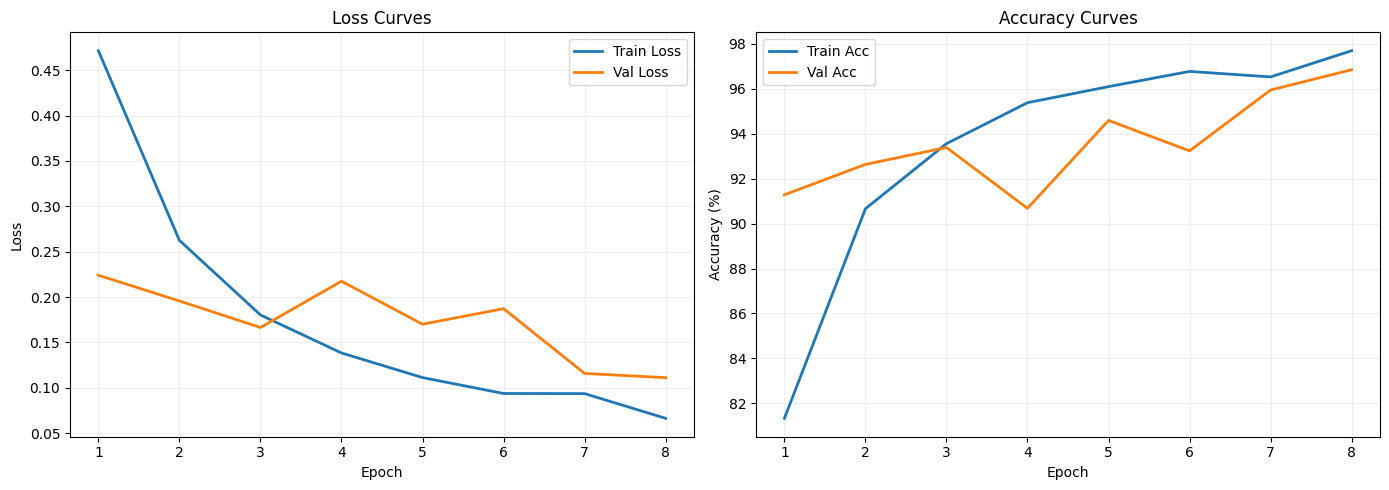

Training curves saved to: /content/drive/MyDrive/CT_Brain/artifacts/brain_stroke_ct_training_curves.png


In [ ]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df['epoch'], history_df['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(history_df['epoch'], history_df['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_title('Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(history_df['epoch'], history_df['train_acc'], label='Train Acc', linewidth=2)
axes[1].plot(history_df['epoch'], history_df['val_acc'], label='Val Acc', linewidth=2)
axes[1].set_title('Accuracy Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig(CURVES_PATH, dpi=120, bbox_inches='tight')
plt.show()
print(f'Training curves saved to: {CURVES_PATH}')

## Cell 8 - Danh Gia Tren Test Set

Cell nay danh gia model tot nhat tren tap test.

No se tao:
- `classification_report` gom precision, recall, f1-score
- `confusion matrix` de xem model hay nham lop nao

Day la cell quan trong nhat de ket luan chat luong model classification.


Classification Report:
              precision    recall  f1-score   support

    bleeding       0.97      0.95      0.96       110
    ischemia       0.98      0.92      0.95       113
      normal       0.98      1.00      0.99       442

    accuracy                           0.98       665
   macro avg       0.98      0.96      0.97       665
weighted avg       0.98      0.98      0.98       665



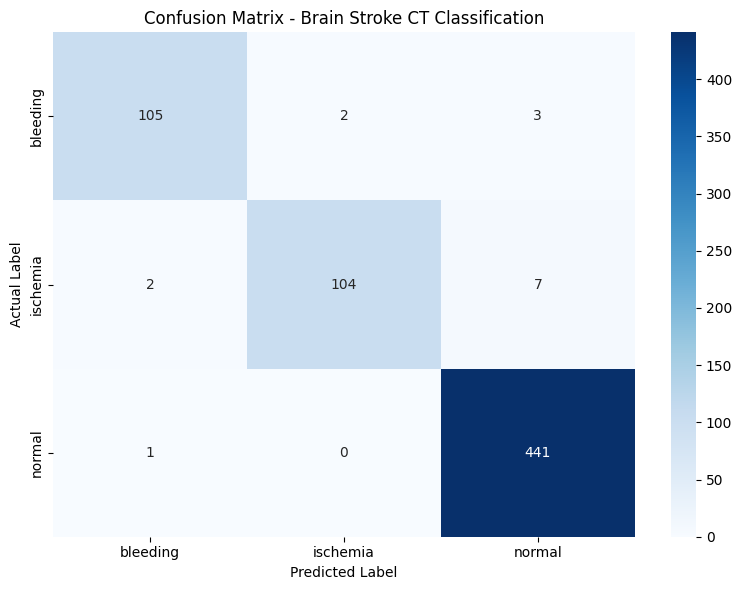

Classification report saved to: /content/drive/MyDrive/CT_Brain/artifacts/brain_stroke_ct_classification_report.json
Confusion matrix saved to: /content/drive/MyDrive/CT_Brain/artifacts/brain_stroke_ct_confusion_matrix.png


In [ ]:
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        preds = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

report_text = classification_report(y_true, y_pred, target_names=class_names)
report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

print('\nClassification Report:')
print(report_text)

with open(REPORT_PATH, 'w', encoding='utf-8') as f:
    json.dump(report_dict, f, ensure_ascii=False, indent=2)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Brain Stroke CT Classification')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig(CONFUSION_MATRIX_PATH, dpi=120, bbox_inches='tight')
plt.show()

print(f'Classification report saved to: {REPORT_PATH}')
print(f'Confusion matrix saved to: {CONFUSION_MATRIX_PATH}')

## Cell 9 - Ham Load Model va Predict 1 Anh

Cell nay dung cho giai doan suy luan va lam giao dien.

Ban se co 3 ham chinh:
- `load_trained_model(...)`: load checkpoint da train
- `preprocess_image(...)`: tien xu ly 1 anh giong luc train
- `predict_image(...)`: tra ve nhan du doan va do tin cay

Sau nay khi lam UI, ban thuong chi can goi `predict_image(image_path, checkpoint_path)`.

In [ ]:
def load_trained_model(checkpoint_path, device=None):
    device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    checkpoint = torch.load(checkpoint_path, map_location=device)

    idx_to_class = checkpoint['idx_to_class']
    idx_to_class = {int(k): v for k, v in idx_to_class.items()}

    model = StrokeCTResNet18(num_classes=len(idx_to_class), use_pretrained=False).to(device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    return model, checkpoint, idx_to_class


def preprocess_image(image_path, image_size, mean, std):
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Could not read image: {image_path}')

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, tuple(image_size))
    image = image.astype(np.float32) / 255.0
    image = (image - np.array(mean, dtype=np.float32)) / np.array(std, dtype=np.float32)
    image = np.transpose(image, (2, 0, 1))
    tensor = torch.from_numpy(image).float().unsqueeze(0)
    return tensor


def predict_image(image_path, checkpoint_path=BEST_MODEL_PATH):
    infer_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model, checkpoint, idx_to_class = load_trained_model(checkpoint_path, infer_device)
    tensor = preprocess_image(
        image_path=image_path,
        image_size=checkpoint['image_size'],
        mean=checkpoint['mean'],
        std=checkpoint['std'],
    ).to(infer_device)

    with torch.no_grad():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)[0]
        pred_idx = int(torch.argmax(probabilities).item())

    return {
        'predicted_index': pred_idx,
        'predicted_label': idx_to_class[pred_idx],
        'confidence': float(probabilities[pred_idx].item()),
        'probabilities': {idx_to_class[i]: float(probabilities[i].item()) for i in range(len(probabilities))},
    }

# Vi du:
# result = predict_image('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/example.png')
# print(result)

In [ ]:
from pathlib import Path

normal_dir = Path('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG')
files = sorted(normal_dir.glob('*'))
print(len(files))
print(files[:10])


4427
[PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10000.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10001.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10004.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10005.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10006.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10008.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10009.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10010.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10011.png'), PosixPath('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10012.png')]


In [ ]:
result = predict_image('/content/data/Brain_Stroke_CT_Dataset/Normal/PNG/10000.png')
print(result)

{'predicted_index': 2, 'predicted_label': 'normal', 'confidence': 0.9999995231628418, 'probabilities': {'bleeding': 1.717599502626399e-07, 'ischemia': 3.4423561601215624e-07, 'normal': 0.9999995231628418}}
